In [ ]:
# Task 1 - Data Import & Setup

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [ ]:
df = pd.read_csv('social_media_engagement_5000.csv')

df.head()

In [6]:
df.shape

(5000, 19)

In [7]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')

In [8]:
df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [9]:
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y'
)

In [10]:
df['posted_at'].dtype

dtype('<M8[us]')

In [11]:
likes_array = np.array(df['likes'].dropna())

print("First 10 Likes:", likes_array[:10])
print("Total Likes:", np.sum(likes_array))
print("Average Likes:", np.mean(likes_array))
print("Maximum Likes:", np.max(likes_array))
print("Minimum Likes:", np.min(likes_array))

First 10 Likes: [ 7011. 11750.  4862.  5350. 12682. 12535. 11703.  9611. 14106.   355.]
Total Likes: 49019162.0
Average Likes: 10107.043711340206
Maximum Likes: 19998.0
Minimum Likes: 10.0


In [13]:
# Task 2 - Data Cleaning

df_clean = df.copy()

In [23]:
df_clean.isnull().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

In [24]:
df_clean.isna().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

In [25]:
df_clean.dropna().shape

(5000, 19)

In [26]:
numeric_columns = ['age', 'likes', 'comments', 'shares']

for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

In [27]:
df_clean[numeric_columns].isnull().sum()

age         0
likes       0
comments    0
shares      0
dtype: int64

In [19]:
categorical_columns = ['gender', 'sentiment']

for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].mode()[0])

In [20]:
df_clean[categorical_columns].isnull().sum()

gender       0
sentiment    0
dtype: int64

In [21]:
df_clean.duplicated().sum()

np.int64(0)

In [22]:
# Remove Duplicate Rows

df_clean = df_clean.drop_duplicates()

# Check duplicates after removal
print("Remaining Duplicate Rows:", df_clean.duplicated().sum())

# Check dataset shape
print("Dataset Shape:", df_clean.shape)


Remaining Duplicate Rows: 0
Dataset Shape: (5000, 19)


In [112]:
df_clean['gender'] = df_clean['gender'].str.strip().str.title()
df_clean['country'] = df_clean['country'].str.strip()
df_clean['post_type'] = df_clean['post_type'].str.strip().str.lower()
df_clean['post_category'] = df_clean['post_category'].str.strip().str.lower()
df_clean['device_type'] = df_clean['device_type'].str.strip().str.lower()
df_clean['sentiment'] = df_clean['sentiment'].str.strip().str.lower()

In [113]:
df_clean[['likes', 'comments', 'shares']].min()

likes       10.0
comments     0.0
shares       0.0
dtype: float64

In [114]:
df_clean[['likes', 'comments', 'shares']].max()

likes       19998.0
comments     2999.0
shares       1999.0
dtype: float64

In [115]:
df_clean['age'].describe()

count    5000.000000
mean       38.440400
std        14.687151
min        13.000000
25%        26.000000
50%        38.000000
75%        51.000000
max        64.000000
Name: age, dtype: float64

In [116]:
df_clean['hashtag_count'] = df_clean['hashtags'].str.count(r'#\w+')

In [117]:
df_clean[['hashtags', 'hashtag_count']].head(10)

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [118]:
df_clean['sentiment'].value_counts()

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64

In [119]:
df_clean['sentiment'].unique()

<ArrowStringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str

In [120]:
df_clean['sentiment'].nunique()

3

In [121]:
df_clean.isnull().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
hashtag_count       0
dtype: int64

In [122]:
df_clean.shape

(5000, 20)

In [123]:
df_clean.duplicated().sum()

np.int64(0)

In [124]:
# Task 3 - Data Exploration Using Pandas

df_clean.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


In [125]:
df_clean.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


In [126]:
df_clean.shape

(5000, 20)

In [127]:
df_clean.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='str')

In [128]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [29]:
df_clean.dtypes

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

In [49]:
df_clean['gender'].unique()

<ArrowStringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: str

In [50]:
df_clean.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,engagement_score
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.00000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,12611.94780
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,193.00000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,7807.00000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,12551.75000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,17478.25000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,24680.00000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,5782.05846


In [51]:
df_clean.describe(include='str')

,gender,country,post_type,post_category,device_type,sentiment,hashtags
count,5000,5000,5000,5000,5000,5000,5000
unique,3,10,4,8,3,3,761
top,Male,India,reel,fitness,mobile,positive,#tech
freq,1849,535,1283,675,1684,2513,201


In [52]:
df_clean['post_type'].value_counts()

post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

In [53]:
df_clean['post_category'].value_counts()

post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64

In [54]:
df_clean['gender'].value_counts()

gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64

In [55]:
df_clean['country'].value_counts()

country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64

In [56]:
df_clean['device_type'].value_counts()

device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: int64

In [57]:
df_clean['sentiment'].value_counts()

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64

In [58]:
df_clean['post_type'].unique()

<ArrowStringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str

In [72]:
df_clean['post_type'].nunique()

4

In [73]:
numeric_df = df_clean.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

correlation_matrix

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,engagement_score
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,0.021868
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,-0.035531
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.012947
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,0.983942
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,0.130552
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.104285
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,0.007616
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,0.005937
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,-0.025467
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.094382


In [74]:
df_clean.groupby('post_type')[['likes', 'comments', 'shares', 'engagement_rate']].mean()

,likes,comments,shares,engagement_rate
post_type,,,,
image,10104.865277,1525.235766,1019.289495,0.895646
reel,10037.802416,1504.187062,982.042089,0.783047
text,10100.148193,1499.106024,1013.989558,1.064549
video,10188.600000,1479.160000,996.834286,1.122365


In [75]:
df_clean.groupby('post_category')['engagement_rate'].mean().sort_values(ascending=False)

post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64

In [76]:
df_clean.groupby('country')['engagement_rate'].mean().sort_values(ascending=False)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

In [77]:
df_clean.groupby('sentiment')[['likes', 'comments', 'shares', 'engagement_rate']].mean()

,likes,comments,shares,engagement_rate
sentiment,,,,
negative,10208.096875,1516.094792,1007.307292,1.038486
neutral,9923.194499,1528.404060,996.565160,0.991170
positive,10180.062077,1480.650617,1005.086749,0.919744


In [117]:
df_clean.groupby('country')['impression_count'].mean().sort_values(ascending=False)

country
India        52462.386916
France       51727.673387
USA          51263.872255
UK           51119.393509
Japan        49616.135593
Brazil       49193.174603
UAE          48928.413519
Canada       48703.150097
Germany      48605.406122
Australia    48346.383367
Name: impression_count, dtype: float64

In [78]:
# Task 4 - Data Wrangling

df_clean['engagement_score'] = (
    df_clean['likes'] +
    df_clean['comments'] +
    df_clean['shares']
)

df_clean[['likes', 'comments', 'shares', 'engagement_score']].head()

,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0


In [79]:
df_clean.shape

(5000, 20)

In [80]:
df_clean.groupby('post_type')['engagement_score'].mean().sort_values(ascending=False)

post_type
video    12664.594286
image    12649.390537
text     12613.243775
reel     12524.031567
Name: engagement_score, dtype: float64

In [81]:
df_clean.groupby('sentiment')['engagement_score'].mean().sort_values(ascending=False)

sentiment
negative    12731.498958
positive    12665.799443
neutral     12448.163720
Name: engagement_score, dtype: float64

In [82]:
df_clean.groupby('country')['engagement_score'].mean().sort_values(ascending=False)

country
France       12903.384073
Australia    12809.621704
UAE          12757.777336
Germany      12635.664286
Canada       12605.894737
Japan        12578.648305
USA          12575.461078
India        12492.701869
Brazil       12385.983135
UK           12384.374239
Name: engagement_score, dtype: float64

In [83]:
df_clean.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'engagement_score'],
      dtype='str')

In [84]:
# Task 5 - Statistical Analysis

metrics = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]
metrics

['likes',
 'comments',
 'shares',
 'watch_time_sec',
 'engagement_rate',
 'follower_count']

In [85]:
df_clean[metrics].agg(['mean', 'median', 'std', 'var'])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
mean,1.010700e+04,1502.039800,1002.91060,4.014503e+03,0.964356,3.936982e+05
median,1.010550e+04,1497.000000,1012.00000,4.034500e+03,0.253896,3.889820e+05
std,5.702293e+03,856.393312,570.85520,2.308096e+03,5.318029,2.309279e+05
var,3.251615e+07,733409.504917,325875.65934,5.327309e+06,28.281435,5.332769e+10


In [86]:
df_clean[metrics].mode().iloc[0]

likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec        916.000000
engagement_rate         0.006363
follower_count     497502.000000
Name: 0, dtype: float64

In [87]:
df_clean[metrics].quantile([0.25, 0.50, 0.75, 0.90, 0.95])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0.25,5235.00,792.00,511.00,2017.75,0.145781,194480.00
0.50,10105.50,1497.00,1012.00,4034.50,0.253896,388982.00
0.75,14959.00,2235.25,1483.00,6020.25,0.504794,589744.25
0.90,18016.30,2695.10,1795.10,7212.10,1.201200,717755.90
0.95,19097.05,2861.00,1901.05,7577.05,2.328526,760174.35


In [88]:
df_clean[metrics].skew()

likes              -0.006894
comments            0.003802
shares             -0.014654
watch_time_sec     -0.018196
engagement_rate    18.781271
follower_count      0.041118
dtype: float64

In [89]:
df_clean[metrics].kurt()

likes               -1.149992
comments            -1.144375
shares              -1.146857
watch_time_sec      -1.195652
engagement_rate    482.991739
follower_count      -1.189474
dtype: float64

In [90]:
# Task 6 - Data Visualization

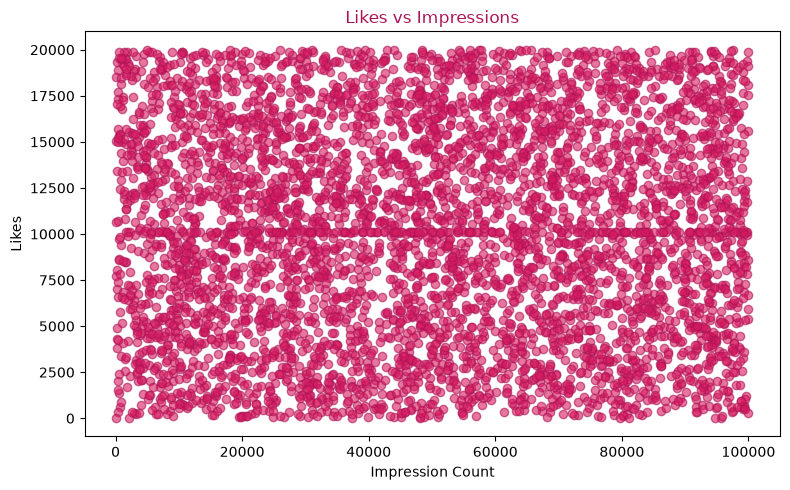

In [91]:
# Visualization 1 - Scatter Plot: Likes vs Impressions
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean['impression_count'],
    df_clean['likes'],
    color='#D81B60',
    alpha=0.6,
    edgecolor='#AD1457'
)

plt.title('Likes vs Impressions', color='#AD1457')
plt.xlabel('Impression Count')
plt.ylabel('Likes')

plt.tight_layout()
plt.show()

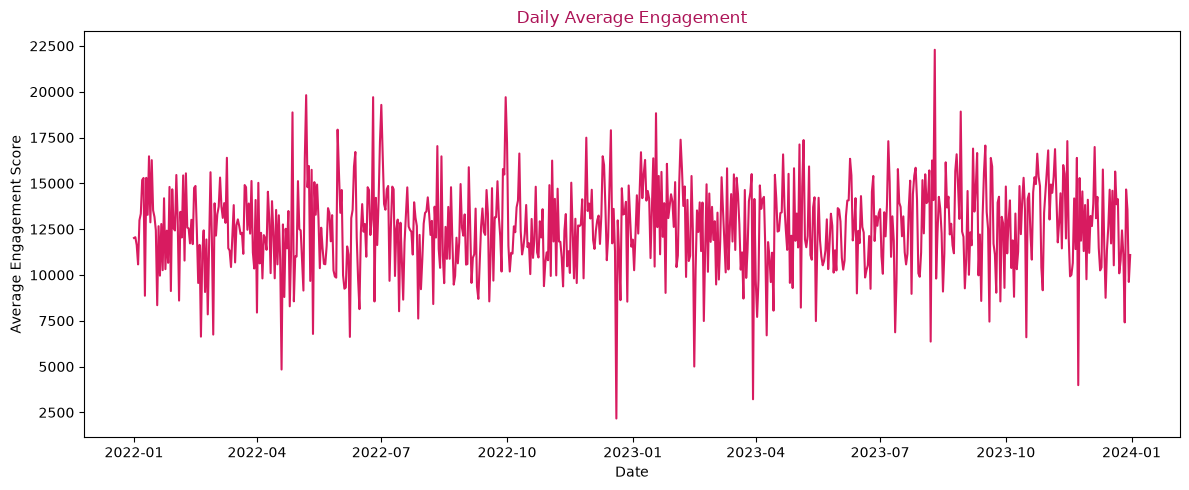

In [92]:
# Visualization 2 - Line Plot: Daily Engagement
daily_engagement = (
    df_clean.groupby('posted_at')['engagement_score']
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily_engagement['posted_at'],
    daily_engagement['engagement_score'],
    color='#D81B60',
    linewidth=1.5
)

plt.title('Daily Average Engagement', color='#AD1457')
plt.xlabel('Date')
plt.ylabel('Average Engagement Score')

plt.tight_layout()
plt.show()

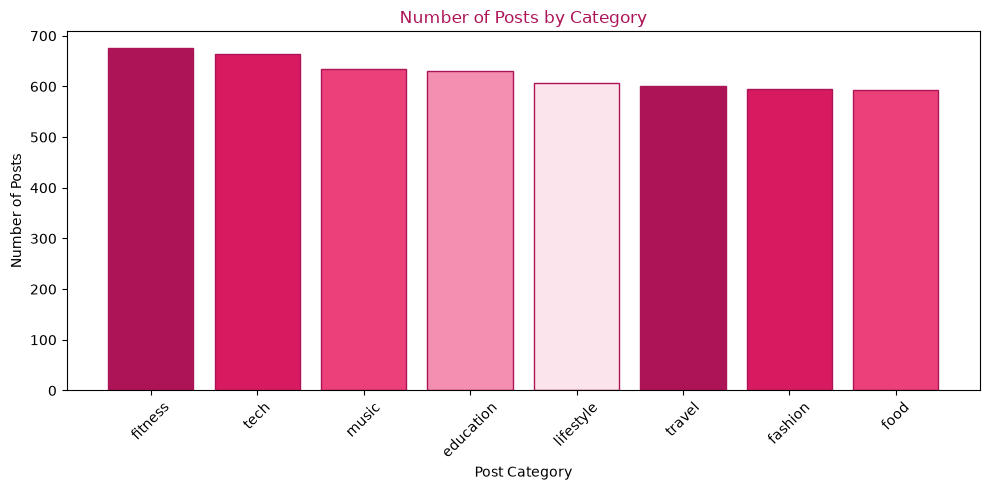

In [93]:
# Visualization 3 - Bar Chart: Number of Posts by Category
category_counts = df_clean['post_category'].value_counts()

rose_colors = [
    '#AD1457',
    '#D81B60',
    '#EC407A',
    '#F48FB1',
    '#FCE4EC',
    '#AD1457',
    '#D81B60',
    '#EC407A'
]

plt.figure(figsize=(10, 5))

plt.bar(
    category_counts.index,
    category_counts.values,
    color=rose_colors,
    edgecolor='#AD1457'
)

plt.title('Number of Posts by Category', color='#AD1457')
plt.xlabel('Post Category')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

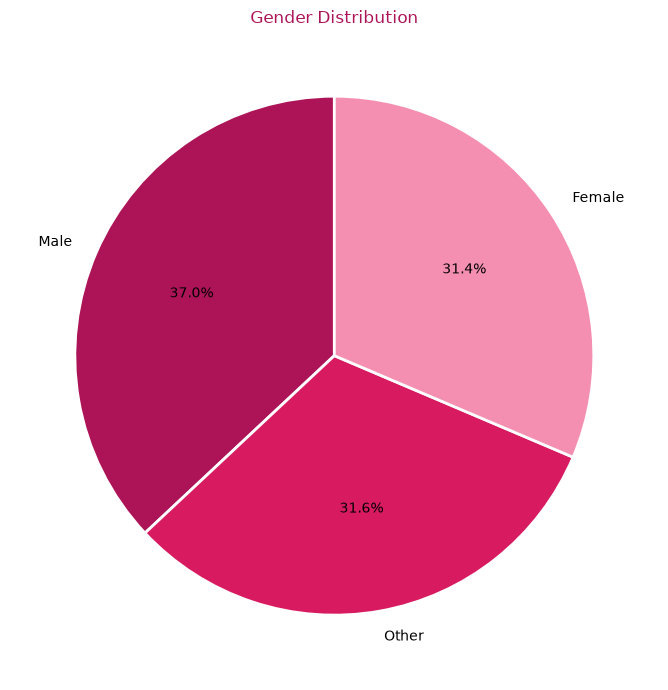

In [94]:
# Visualization 4 - Pie Chart: Gender Distribution
gender_counts = df_clean['gender'].value_counts()

rose_colors = ['#AD1457', '#D81B60', '#F48FB1']

plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    colors=rose_colors,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

plt.title('Gender Distribution', color='#AD1457')

plt.tight_layout()
plt.show()

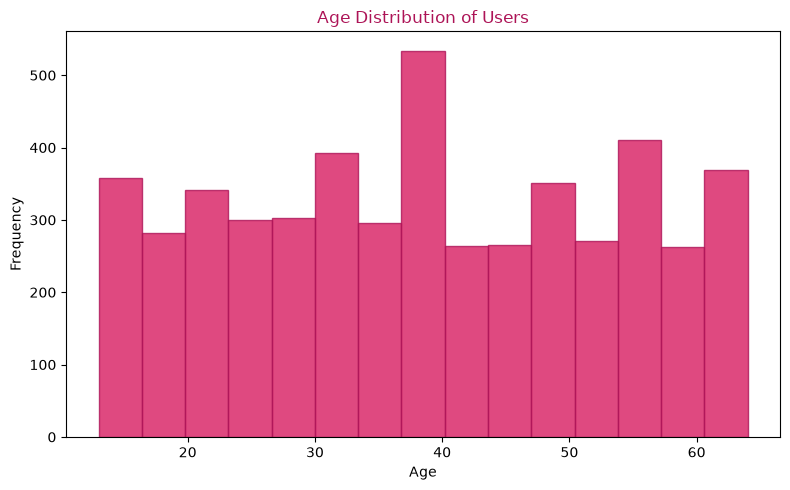

In [95]:
# Visualization 5 - Histogram: Age Distribution
plt.figure(figsize=(8, 5))

plt.hist(
    df_clean['age'],
    bins=15,
    color='#D81B60',
    edgecolor='#AD1457',
    alpha=0.8
)

plt.title('Age Distribution of Users', color='#AD1457')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

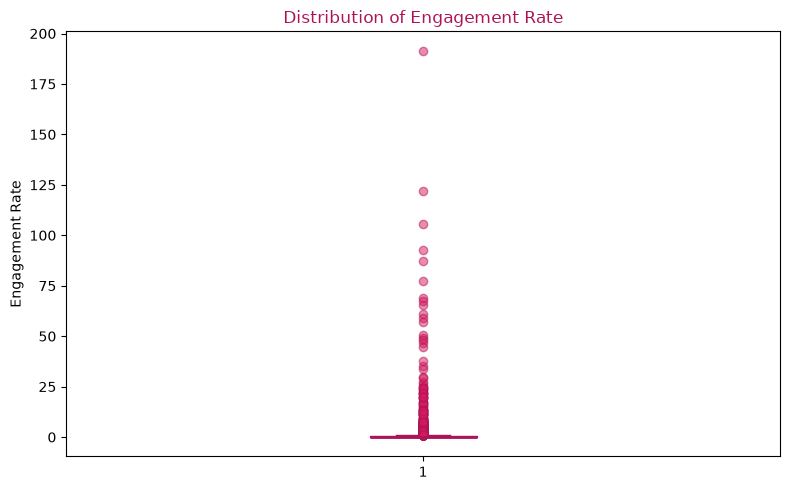

In [96]:
# Visualization 6 - Box Plot: Engagement Rate
plt.figure(figsize=(8, 5))

plt.boxplot(
    df_clean['engagement_rate'],
    patch_artist=True,
    boxprops={'facecolor': '#F48FB1', 'edgecolor': '#AD1457'},
    medianprops={'color': '#AD1457', 'linewidth': 2},
    whiskerprops={'color': '#AD1457'},
    capprops={'color': '#AD1457'},
    flierprops={
        'markerfacecolor': '#D81B60',
        'markeredgecolor': '#AD1457',
        'marker': 'o',
        'alpha': 0.5
    }
)

plt.title('Distribution of Engagement Rate', color='#AD1457')
plt.ylabel('Engagement Rate')

plt.tight_layout()
plt.show()

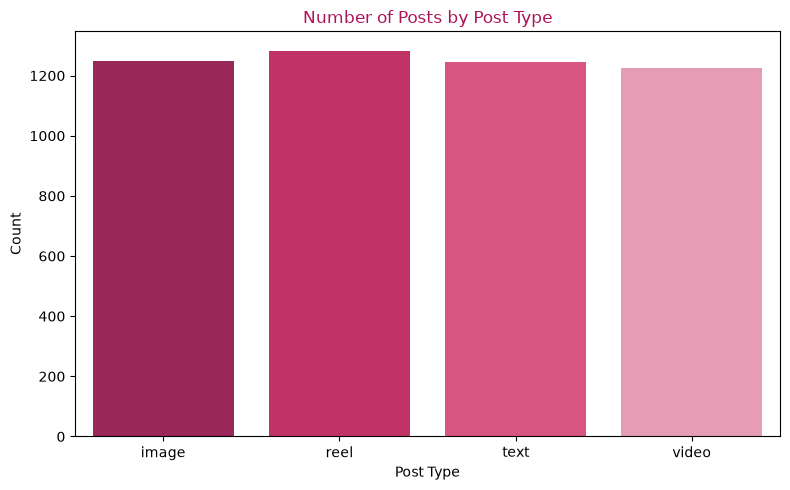

In [97]:
# Visualization 7 - Seaborn Count Plot: Posts by Post Type
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='post_type',
    hue='post_type',
    palette=['#AD1457', '#D81B60', '#EC407A', '#F48FB1'],
    legend=False
)

plt.title('Number of Posts by Post Type', color='#AD1457')
plt.xlabel('Post Type')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

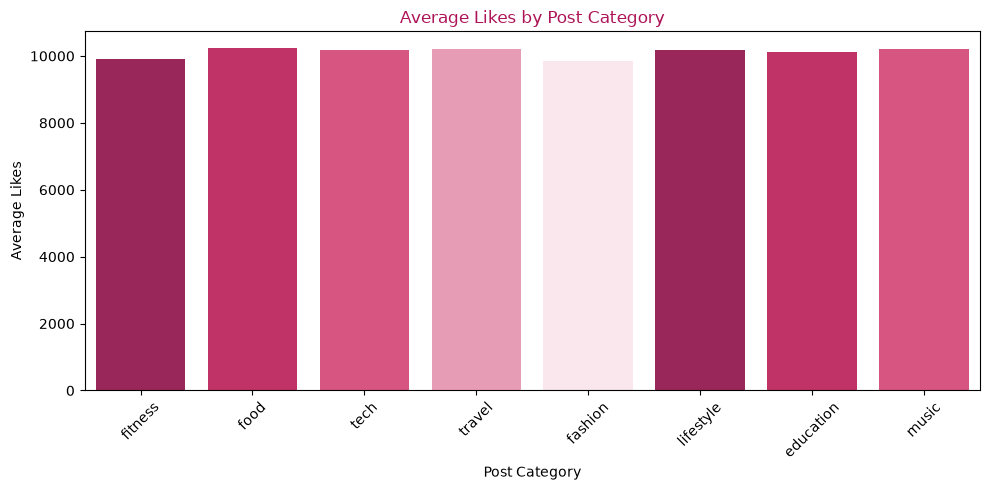

In [98]:
# Visualization 8 - Seaborn Bar Plot: Average Likes by Category
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_clean,
    x='post_category',
    y='likes',
    hue='post_category',
    palette=['#AD1457', '#D81B60', '#EC407A', '#F48FB1',
             '#FCE4EC', '#AD1457', '#D81B60', '#EC407A'],
    errorbar=None,
    legend=False
)

plt.title('Average Likes by Post Category', color='#AD1457')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

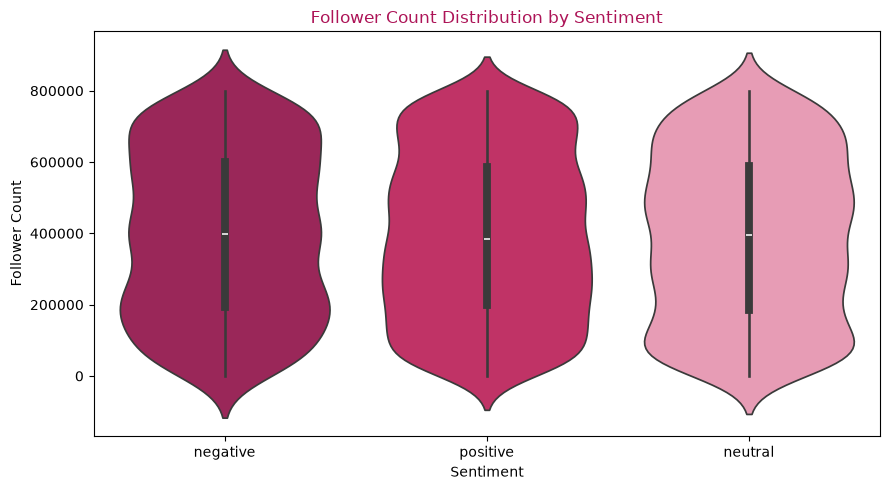

In [99]:
# Visualization 9 - Seaborn Violin Plot: Followers by Sentiment
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df_clean,
    x='sentiment',
    y='follower_count',
    hue='sentiment',
    palette=['#AD1457', '#D81B60', '#F48FB1'],
    legend=False
)

plt.title('Follower Count Distribution by Sentiment', color='#AD1457')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')

plt.tight_layout()
plt.show()

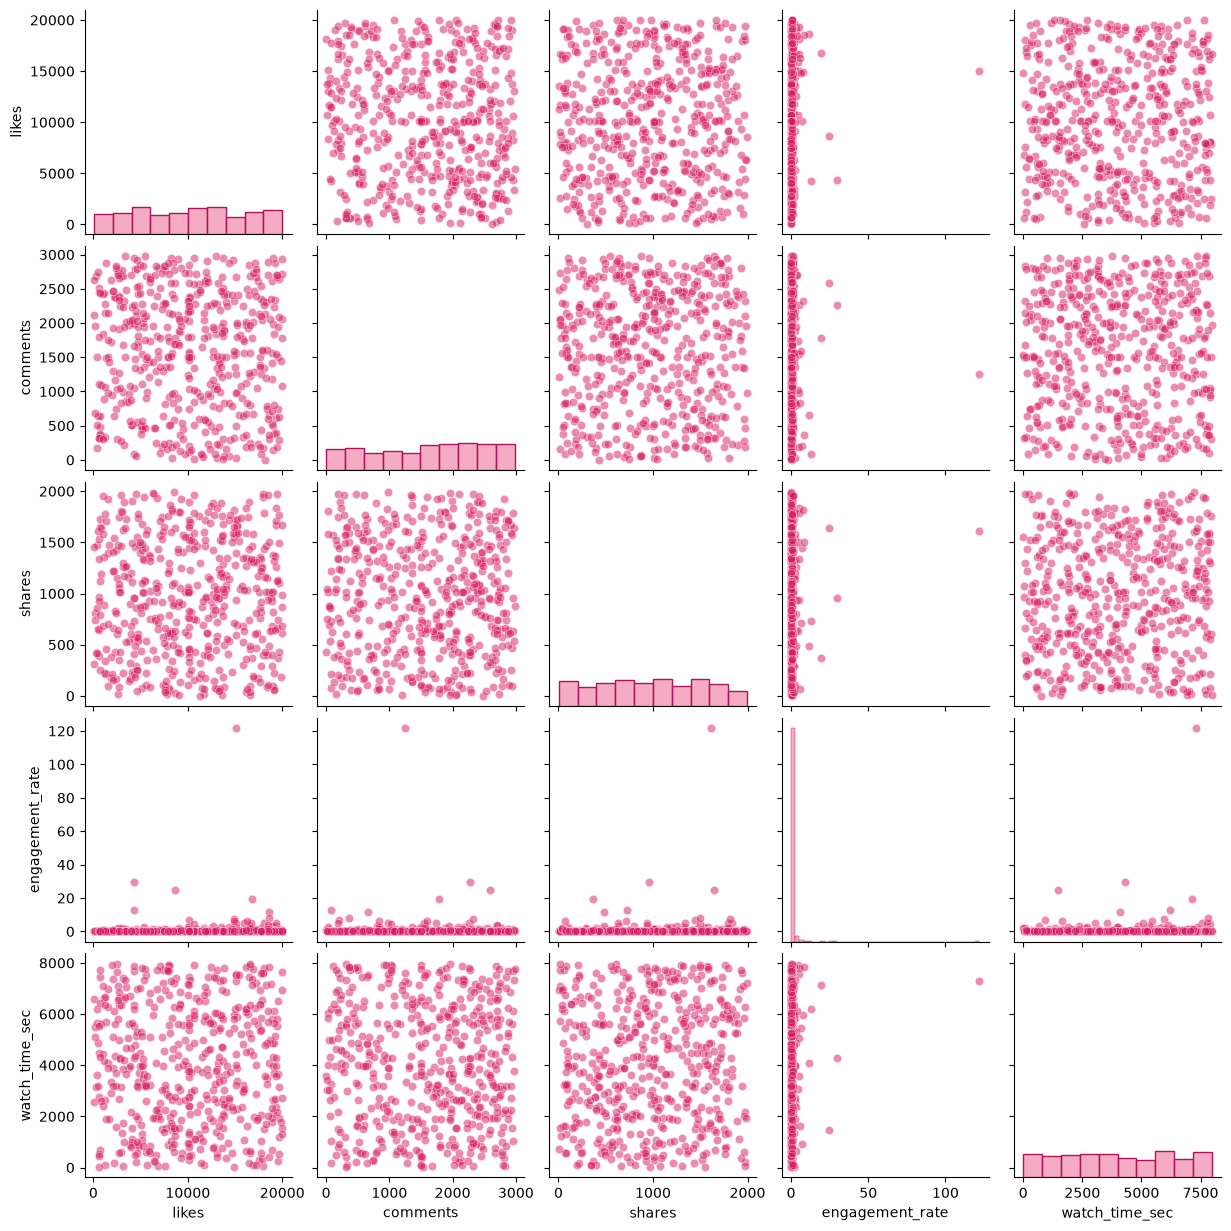

In [100]:
# Visualization 10 - Seaborn Pair Plot: Numerical Features
pairplot_data = df_clean[
    ['likes', 'comments', 'shares', 'engagement_rate', 'watch_time_sec']
].sample(500, random_state=42)

sns.pairplot(
    pairplot_data,
    diag_kind='hist',
    plot_kws={'color': '#D81B60', 'alpha': 0.5},
    diag_kws={'color': '#F48FB1', 'edgecolor': '#AD1457'}
)

plt.show()

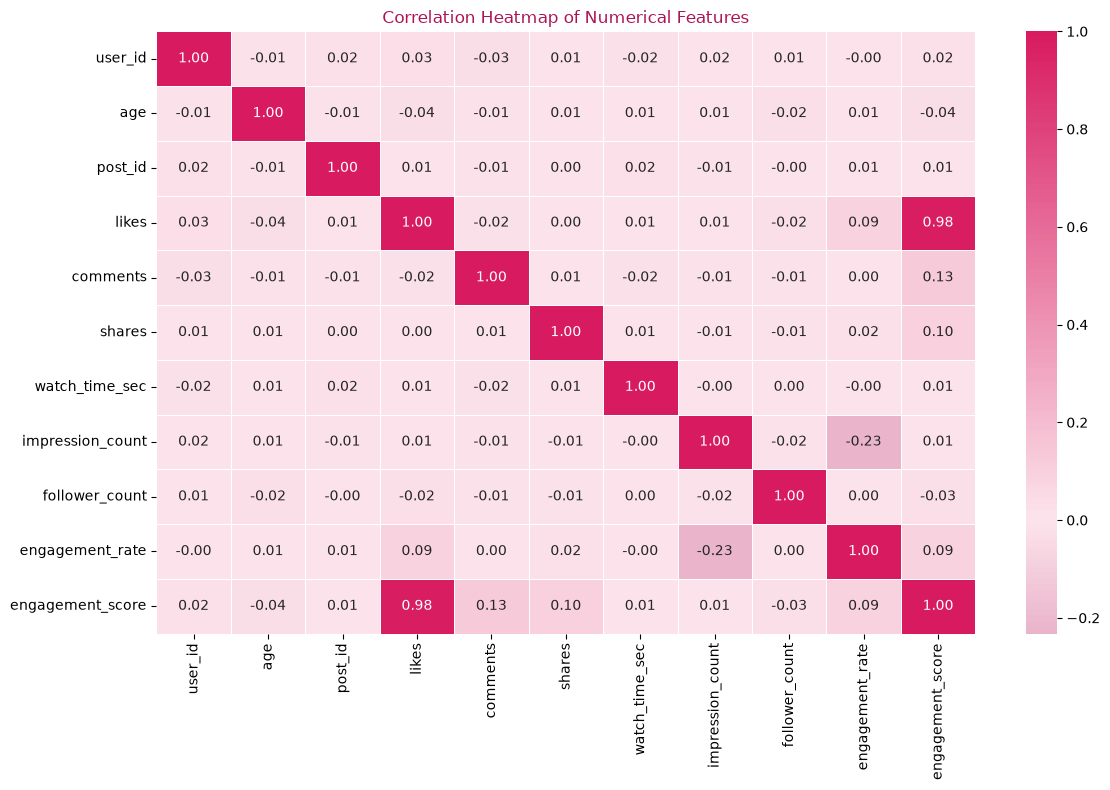

In [101]:
# Visualization 11 - Seaborn Heatmap: Correlation Matrix

from matplotlib.colors import LinearSegmentedColormap

rose_cmap = LinearSegmentedColormap.from_list(
    'Pastel_Rose',
    ['#AD1457', '#FCE4EC', '#D81B60']
)

correlation_matrix = df_clean.select_dtypes(
    include='number'
).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap=rose_cmap,
    center=0,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features', color='#AD1457')

plt.tight_layout()
plt.show()

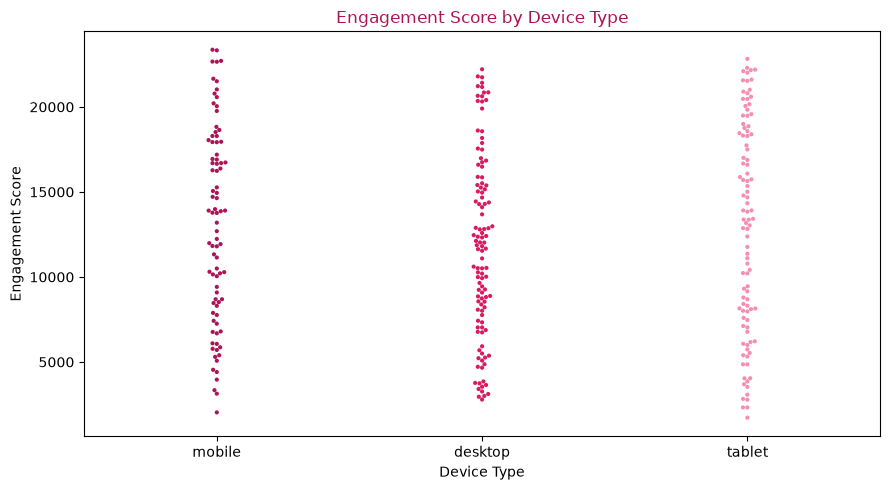

In [102]:
# Visualization 12 - Seaborn Swarm Plot: Engagement Score by Device Type
swarm_data = df_clean.sample(300, random_state=42)

plt.figure(figsize=(9, 5))

sns.swarmplot(
    data=swarm_data,
    x='device_type',
    y='engagement_score',
    hue='device_type',
    palette=['#AD1457', '#D81B60', '#F48FB1'],
    legend=False,
    size=3
)

plt.title('Engagement Score by Device Type', color='#AD1457')
plt.xlabel('Device Type')
plt.ylabel('Engagement Score')

plt.tight_layout()
plt.show()

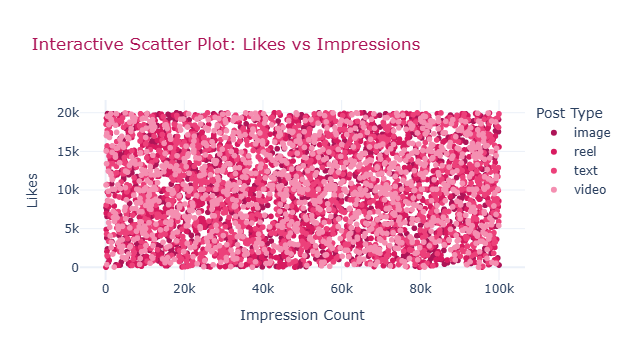

In [103]:
# Visualization 13 - Plotly Interactive Scatter Plot: Likes vs Impressions
fig = px.scatter(
    df_clean,
    x='impression_count',
    y='likes',
    color='post_type',
    color_discrete_sequence=[
        '#AD1457',
        '#D81B60',
        '#EC407A',
        '#F48FB1',
        '#FCE4EC'
    ],
    title='Interactive Scatter Plot: Likes vs Impressions',
    labels={
        'impression_count': 'Impression Count',
        'likes': 'Likes',
        'post_type': 'Post Type'
    },
    hover_data=['engagement_score', 'post_category']
)

fig.update_layout(
    title_font_color='#AD1457',
    template='plotly_white'
)

fig.show()

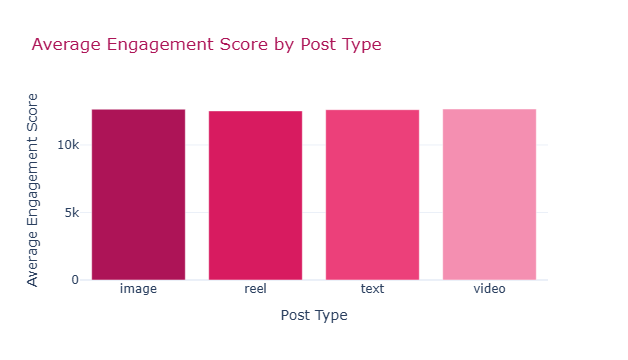

In [104]:
# Visualization 14 - Plotly Interactive Bar Chart: Average Engagement by Post Type
post_type_engagement = (
    df_clean.groupby('post_type')['engagement_score']
    .mean()
    .reset_index()
)

fig = px.bar(
    post_type_engagement,
    x='post_type',
    y='engagement_score',
    color='post_type',
    color_discrete_sequence=[
        '#AD1457',
        '#D81B60',
        '#EC407A',
        '#F48FB1'
    ],
    title='Average Engagement Score by Post Type',
    labels={
        'post_type': 'Post Type',
        'engagement_score': 'Average Engagement Score'
    }
)

fig.update_layout(
    title_font_color='#AD1457',
    template='plotly_white',
    showlegend=False
)

fig.show()

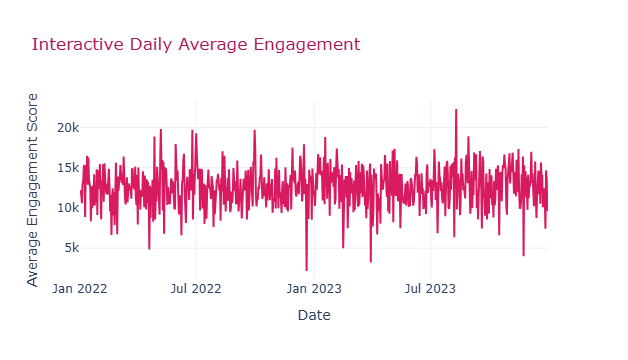

In [105]:
# Visualization 15 - Plotly Interactive Line Chart: Daily Engagement
daily_engagement = (
    df_clean.groupby('posted_at')['engagement_score']
    .mean()
    .reset_index()
)

fig = px.line(
    daily_engagement,
    x='posted_at',
    y='engagement_score',
    title='Interactive Daily Average Engagement',
    labels={
        'posted_at': 'Date',
        'engagement_score': 'Average Engagement Score'
    }
)

fig.update_traces(
    line=dict(color='#D81B60', width=2)
)

fig.update_layout(
    title_font_color='#AD1457',
    template='plotly_white'
)

fig.show()

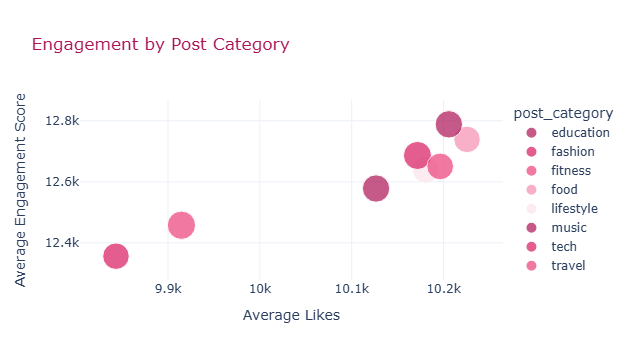

In [106]:
# Visualization 16 - Plotly Interactive Bubble Chart: Engagement by Post Category
category_engagement = (
    df_clean.groupby('post_category')
    .agg(
        average_likes=('likes', 'mean'),
        average_engagement=('engagement_score', 'mean'),
        total_posts=('post_id', 'count')
    )
    .reset_index()
)

fig = px.scatter(
    category_engagement,
    x='average_likes',
    y='average_engagement',
    size='total_posts',
    color='post_category',
    color_discrete_sequence=[
        '#AD1457',
        '#D81B60',
        '#EC407A',
        '#F48FB1',
        '#FCE4EC'
    ],
    hover_name='post_category',
    hover_data=['total_posts'],
    title='Engagement by Post Category',
    labels={
        'average_likes': 'Average Likes',
        'average_engagement': 'Average Engagement Score',
        'total_posts': 'Total Posts'
    }
)

fig.update_layout(
    title_font_color='#AD1457',
    template='plotly_white'
)

fig.show()

# Final Insights and Findings

In [107]:
# Highest Engagement by Post Type

post_type_performance = df_clean.groupby('post_type')['engagement_rate'].mean().sort_values(ascending=False)

print("Average Engagement Rate by Post Type:")
print(post_type_performance)

print("\nHighest Performing Post Type:")
print(post_type_performance.idxmax())

Average Engagement Rate by Post Type:
post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64

Highest Performing Post Type:
video


### 1. Content Performance – Post Type

Video posts have the highest average engagement rate (1.1224), followed by text posts (1.0645), image posts (0.8956), and reels (0.7830).

**Insight:** Video content performs best in terms of average engagement rate among the post types in this dataset.

In [108]:
category_performance = df_clean.groupby('post_category')['engagement_rate'].mean().sort_values(ascending=False)

print("Average Engagement Rate by Post Category:")
print(category_performance)

print("\nHighest Performing Post Category:")
print(category_performance.idxmax())

Average Engagement Rate by Post Category:
post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64

Highest Performing Post Category:
food


### 2. Content Performance – Post Category

Food posts have the highest average engagement rate (1.3586), followed by tech (1.1605), lifestyle (1.0910), music (0.8888), fitness (0.8656), education (0.8442), fashion (0.8071), and travel (0.7022).

**Insight:** Food is the best-performing post category in terms of average engagement rate in this dataset.

In [109]:
country_performance = df_clean.groupby('country')['engagement_rate'].mean().sort_values(ascending=False)

print("Average Engagement Rate by Country:")
print(country_performance)

print("\nCountry with Highest Average Engagement Rate:")
print(country_performance.idxmax())

Average Engagement Rate by Country:
country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

Country with Highest Average Engagement Rate:
Brazil


### 3. Content Performance – Country

Brazil has the highest average engagement rate (1.5407), followed by Australia (1.3243), France (1.1464), UAE (1.1124), Canada (0.9167), UK (0.8510), Japan (0.7696), Germany (0.7590), India (0.6550), and USA (0.5766).

**Insight:** Brazil is the highest-performing country in terms of average engagement rate in this dataset, while the USA has the lowest.

In [110]:
age_engagement = df_clean.groupby('age')['engagement_rate'].mean().sort_values(ascending=False)

print("Average Engagement Rate by Age:")
print(age_engagement)

print("\nAge with Highest Average Engagement Rate:")
print(age_engagement.idxmax())

Average Engagement Rate by Age:
age
24.0    2.897327
55.0    2.599106
51.0    2.397295
48.0    1.675878
50.0    1.552627
41.0    1.540070
35.0    1.521596
47.0    1.402015
42.0    1.350772
63.0    1.303909
33.0    1.277557
30.0    1.270129
16.0    1.226848
29.0    1.110432
25.0    1.041681
38.0    1.035114
62.0    1.005127
14.0    1.003067
54.0    1.002622
49.0    0.999235
40.0    0.930504
23.0    0.922448
57.0    0.919751
18.0    0.888391
52.0    0.867426
17.0    0.858763
44.0    0.795102
27.0    0.775328
60.0    0.759586
15.0    0.714170
53.0    0.707924
19.0    0.676687
46.0    0.663994
36.0    0.609569
22.0    0.586786
32.0    0.581710
43.0    0.566439
34.0    0.557236
61.0    0.553854
56.0    0.524008
20.0    0.515541
45.0    0.513521
26.0    0.501467
59.0    0.495578
37.0    0.494109
13.0    0.455583
21.0    0.452752
31.0    0.440684
39.0    0.436184
58.0    0.435130
64.0    0.402533
28.0    0.385081
Name: engagement_rate, dtype: float64

Age with Highest Average Engagement Rate:

### 4. User Trends – Age and Engagement

The analysis shows that users aged 24 have the highest average engagement rate (2.8973), followed by users aged 55 (2.5991) and 51 (2.3973).

**Insight:** Among the age groups in this dataset, users aged 24 show the highest average engagement rate. This indicates that engagement levels vary across different age groups.

In [111]:
verified_performance = df_clean.groupby('is_verified')['engagement_rate'].mean().sort_values(ascending=False)

print("Average Engagement Rate by Verification Status:")
print(verified_performance)

Average Engagement Rate by Verification Status:
is_verified
True     1.054250
False    0.954744
Name: engagement_rate, dtype: float64


### 5. User Trends – Verified Account Performance

Verified accounts have an average engagement rate of 1.0543, while non-verified accounts have an average engagement rate of 0.9547.

**Insight:** Verified accounts show a higher average engagement rate than non-verified accounts in this dataset.

In [112]:
df_clean['posted_at'] = pd.to_datetime(df_clean['posted_at'])

df_clean['post_hour'] = df_clean['posted_at'].dt.hour

hourly_impressions = df_clean.groupby('post_hour')['impression_count'].mean().sort_values(ascending=False)

print("Average Impressions by Hour:")
print(hourly_impressions)

print("\nHour with Highest Average Impressions:")
print(hourly_impressions.idxmax())

Average Impressions by Hour:
post_hour
0    50013.7328
Name: impression_count, dtype: float64

Hour with Highest Average Impressions:
0


In [113]:
print("Sample Posted Dates and Times:")
print(df_clean['posted_at'].head(10))

print("\nNumber of Unique Posting Hours:")
print(df_clean['post_hour'].nunique())

Sample Posted Dates and Times:
0   2022-12-17
1   2023-06-02
2   2023-05-07
3   2023-02-12
4   2023-05-23
5   2023-09-16
6   2022-04-15
7   2023-12-20
8   2023-07-06
9   2022-11-16
Name: posted_at, dtype: datetime64[us]

Number of Unique Posting Hours:
1


### 6. Behavioural Analysis – Posting Time and Impressions

The posted_at column contains date information only and does not include actual posting times. Therefore, all records were assigned hour 0 (12:00 AM) during the time extraction process.

**Insight:** The best time of day for impressions cannot be determined from the available dataset because actual posting time information is not provided.

In [114]:
device_watch_time = df_clean.groupby('device_type')['watch_time_sec'].mean().sort_values(ascending=False)

print("Average Watch Time by Device Type:")
print(device_watch_time)

print("\nDevice with Highest Average Watch Time:")
print(device_watch_time.idxmax())

Average Watch Time by Device Type:
device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64

Device with Highest Average Watch Time:
mobile


### 7. Behavioural Analysis – Device Type and Watch Time

Mobile users have the highest average watch time (4087.83 seconds), followed by tablet users (3979.74 seconds) and desktop users (3974.79 seconds).

**Insight:** Mobile devices show the highest average watch time among the three device types in this dataset.

In [115]:
sentiment_performance = df_clean.groupby('sentiment')['engagement_rate'].mean().sort_values(ascending=False)

print("Average Engagement Rate by Sentiment:")
print(sentiment_performance)

print("\nSentiment with Highest Average Engagement Rate:")
print(sentiment_performance.idxmax())

Average Engagement Rate by Sentiment:
sentiment
negative    1.038486
neutral     0.991170
positive    0.919744
Name: engagement_rate, dtype: float64

Sentiment with Highest Average Engagement Rate:
negative


### 8. Sentiment Analysis – Engagement Performance

Negative sentiment has the highest average engagement rate (1.0385), followed by neutral sentiment (0.9912) and positive sentiment (0.9197).

**Insight:** Negative sentiment posts show the highest average engagement rate among the three sentiment categories in this dataset.

In [ ]:
sentiment_metrics = df_clean.groupby('sentiment')[
    ['likes', 'comments', 'shares', 'impression_count', 'watch_time_sec', 'engagement_rate']
].mean().round(2)

print("Average Performance Metrics by Sentiment:")
print(sentiment_metrics)

### 9. Sentiment Analysis – Negative and Neutral Post Behaviour

Negative posts have the highest average likes (10,208.10), shares (1,007.31), watch time (4,054.64 seconds), and engagement rate (1.04).

Neutral posts have the highest average comments (1,528.40), while positive posts have the highest average impressions (50,248.11).

**Insight:** Negative posts show stronger performance in likes, shares, watch time, and engagement rate. Neutral posts receive slightly more comments, while positive posts generate the highest average impressions.